In [ ]:
import sys
import os
import pandas as pd
import numpy as np
import shap
sys.path.append(os.path.abspath(".."))
from churn.modelo import dividir_datos, construir_modelo
from churn.datos import cargar_datos
from churn.eda import graficar_tasa
from churn.metricas import precision_at_k, lift_at_k, tabla_ganancias
from churn.explicacion import calcular_shap
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression

/home/diego/Proyectos/churn-sdg/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

In [3]:
df = cargar_datos("../data/dataset.csv")

In [4]:
X_train, X_test, y_train, y_test = dividir_datos(df)

In [5]:
num_cols = [
    "rev_Mean",         # Mean monthly revenue (charge amount)
    "mou_Mean",         # Mean number of monthly minutes of use
    "ovrrev_Mean",      # Mean overage revenue
    "comp_dat_Mean",    # Mean number of completed data calls
    "custcare_Mean",    # Mean number of customer care calls
    "phones",           # Number of handsets issued
    "months",           # Total number of months in service
    "eqpdays",          # Number of days (age) of current mobile phone
    "change_mou",       # Percentage change in monthly minutes of use vs previous three month average
    "change_rev",       # Percentage change in monthly revenue vs previous three month average
    "drop_vce_Mean",    # Mean number of dropped (failed) voice calls
    "drop_dat_Mean",    # Mean number of dropped (failed) data calls
    "drop_blk_Mean",    # Mean number of dropped or blocked calls
    "blck_vce_Mean",    # Mean number of blocked (failed) voice calls
    "blck_dat_Mean",    # Mean number of blocked (failed) data calls
    "unan_dat_Mean",    # Mean number of unanswered data calls
    "totmrc_Mean",      # Mean total monthly recurring charge
    "uniqsubs",         # Number of unique subscribers in the household
    "roam_Mean",        # Mean number of roaming calls
    "datovr_Mean",      # Mean revenue of data overage
    "da_Mean",          # Mean number of directory assisted calls
    "recv_sms_Mean",    # Mean number of received sms
    "callfwdv_Mean",    # Mean number of call forwarding calls
    "callwait_Mean",    # Mean number of call waiting calls
    "threeway_Mean",    # Mean number of three way calls
    "hnd_price",        # Current handset price
]

In [6]:
cat_cols = [
    "refurb_new",   # Handset: refurbished or new
    "infobase",     # InfoBase match
    "dualband",     # Dualband
    "asl_flag",     # Account spending limit
    "hnd_webcap",   # Handset web capability
]

In [7]:
config_regularizada = LGBMClassifier(
    learning_rate= 0.05,   
    n_estimators= 300,      
    num_leaves= 15,        
    max_depth= 5,          
    min_child_samples= 50, 
    colsample_bytree= 0.8, 
    reg_alpha= 0.1,        
    reg_lambda= 0.5,       
    random_state= 42,
    verbose=-1
)

In [8]:
pipeline_lgbm = construir_modelo(num_cols, cat_cols,config_regularizada,False)
pipeline_lgbm.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('limpieza', ...), ('pre', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](98,)","['rev_Mean','mou_Mean','totmrc_Mean',...,'kid16_17','creditcd','eqpdays']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,98
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function lim...x79a29fc70720>
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",'one-to-one'
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None


In [9]:
X_muestra, valores = calcular_shap(pipeline_lgbm, X_test, 2000, 42)

i = 0
prob_shap = sigmoid(valores.base_values + valores.values.sum(axis=1))    # un valor por cliente
prob_modelo = pipeline_lgbm.predict_proba(X_muestra)[:, 1]
np.allclose(prob_shap, prob_modelo, atol=1e-6)                           # debe dar True

True

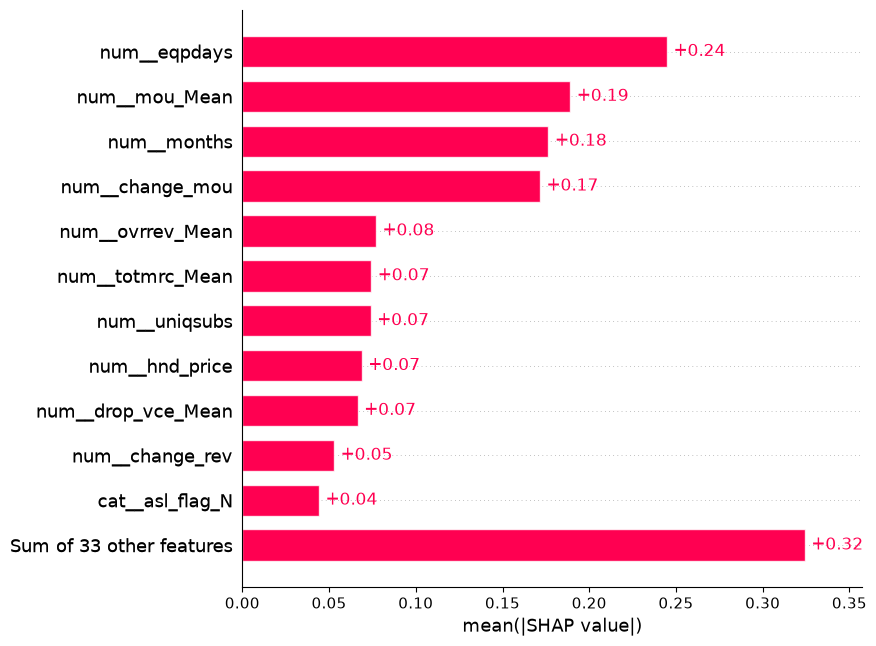

In [10]:
shap.plots.bar(valores, max_display=12)           # global: importancia media

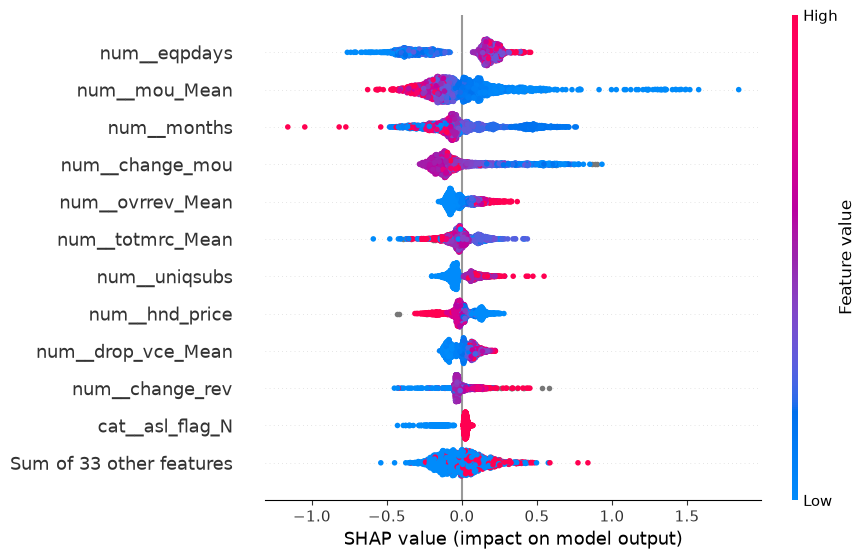

In [11]:
shap.plots.beeswarm(valores, max_display=12)      # global + dirección

In [12]:
from sklearn.inspection import permutation_importance

X_perm = X_test.sample(5000, random_state=42)
y_perm = y_test.loc[X_perm.index]       # etiquetas reales de esos mismos clientes

resultado_perm = permutation_importance(
    pipeline_lgbm, X_perm, y_perm,
    scoring="roc_auc",
    n_repeats=5,     # desordena cada columna 5 veces y promedia
    random_state=42,
    n_jobs=-1
)

In [13]:
importancia_perm = pd.Series(
    resultado_perm.importances_mean,
    index=X_perm.columns
).sort_values(ascending=False)

importancia_perm.head(8)

mou_Mean       0.049906
months         0.039679
change_mou     0.037640
eqpdays        0.036012
totmrc_Mean    0.015954
change_rev     0.007580
ovrrev_Mean    0.006757
uniqsubs       0.006057
dtype: float64

In [14]:
top_permutacion = pd.DataFrame({
    'Feature': X_perm.columns,
    'Importancia': resultado_perm.importances_mean
}).sort_values('Importancia', ascending=False)['Feature'].tolist()

In [15]:
nombres_transformados = pipeline_lgbm[:-1].get_feature_names_out()

top_shap = pd.DataFrame({
    'Feature': (nombre.replace("num__","").replace("cat__","") for nombre in nombres_transformados),
    'Importancia': np.abs(valores.values).mean(axis=0)
}).sort_values('Importancia', ascending=False)['Feature'].tolist()

In [16]:
from churn.eda import tasa_por_decil

numeric_cols = df.select_dtypes(include='number').columns.drop(['churn','Customer_ID'])

dif_tasas = pd.Series(
    {
        col: (t := tasa_por_decil(df, col, dropna=True)['tasa_churn']).max() - t.min()
        for col in numeric_cols
    },
    name="dif_tasa_churn"
).sort_values(ascending=False)

top_eda_univariado = dif_tasas[:8].index.to_list()

In [17]:
tabla_comparativa = pd.DataFrame({
    'Ranking': range(1, 9),
    'SHAP (LightGBM)': top_shap[:8],
    'Permutación (ROC-AUC)': top_permutacion[:8],
    'EDA Univariado': top_eda_univariado[:8]
}).set_index('Ranking')

display(tabla_comparativa)

,SHAP (LightGBM),Permutación (ROC-AUC),EDA Univariado
Ranking,,,
1,eqpdays,mou_Mean,months
2,mou_Mean,months,eqpdays
3,months,change_mou,hnd_price
4,change_mou,eqpdays,mou_Mean
5,ovrrev_Mean,totmrc_Mean,totmrc_Mean
6,totmrc_Mean,change_rev,avg3mou
7,uniqsubs,ovrrev_Mean,mou_opkv_Mean
8,hnd_price,uniqsubs,complete_Mean


`hnd_price` era la tercera variable en el EDA y en SHAP cayó al octavo lugar. SHAP tiene ciertos límites, uno de ellos es que las variables correlacionadas se reparten el crédito, igual que con los coeficientes. Como se vió en el EDA, la variable `hnd_price` tenía relación con la variable `hnd_webcap`. Cuando se agrupo por webcap y se sacó la media de price, se vió que los valores más chicos estaban en NA y WC, mismos que su tasa de churn estaban por encima de la media y el valor más alto estaba en WCMB, mismo que tenía la tasa de churn más baja. Cuando vimos cómo se comportaba la tasa por rango de price, mientras más aumentaba el price, menor el riesgo de churn. Con esto podemos ver que una explica a la otra, a mayor precio, mejor calidad (WCMB) y menor riesgo de churn y a menor precio, menor calidad (NA y WC) y mayor riesgo de churn.
Esto último demuestra que las variables están correlacionadas y por tanto SHAP reparte el crédito haciendo que hnd_price baje en el ranking.

In [18]:
dif_tasas[:20]

months           0.287964
eqpdays          0.236783
hnd_price        0.214425
mou_Mean         0.146531
totmrc_Mean      0.131568
avg3mou          0.128536
mou_opkv_Mean    0.127769
complete_Mean    0.127284
comp_vce_Mean    0.126524
peak_vce_Mean    0.126496
attempt_Mean     0.124735
plcd_vce_Mean    0.123576
mou_cvce_Mean    0.123300
mou_peav_Mean    0.123243
opk_vce_Mean     0.120401
adjrev           0.119853
totrev           0.118000
avg3qty          0.114675
change_mou       0.098689
avg6mou          0.094526
Name: dif_tasa_churn, dtype: float64

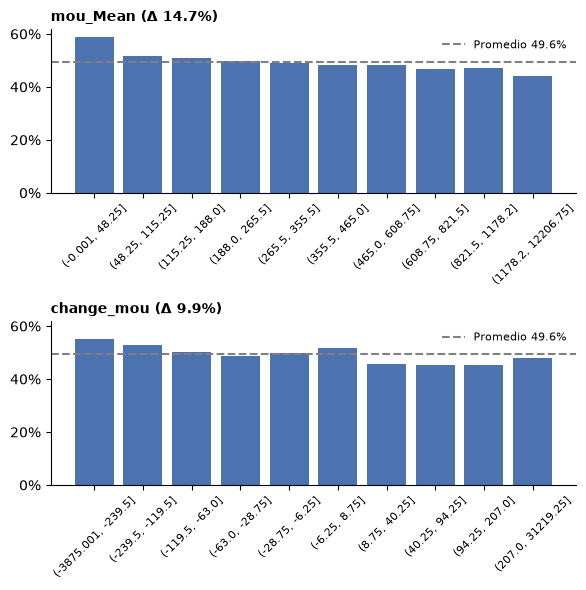

In [19]:
import matplotlib.pyplot as plt
from churn.eda import tasa_por_decil, graficar_tasa

promedio_global = df["churn"].mean()
fig, axes = plt.subplots(2, 1, figsize=(6,6), sharey=True)

for col, ax in zip(["mou_Mean", "change_mou"], axes.flatten()):
    tabla_decil = tasa_por_decil(df, col, dropna=True)
    graficar_tasa(
        tabla=tabla_decil,
        titulo=f"{col} (Δ {dif_tasas[col]:.1%})",
        promedio=promedio_global,
        ax=ax
    )

plt.tight_layout()
plt.show()


mou_Mean y change_mou estaban en el top 4 y 19, respectivamente. En SHAP pasaron a 2 y 4, lo que quiere decir que subieron mucho. Esto se debe a que LGBM utiliza un modelo de árboles, lo que permite, por una parte es poder representar mejor patrones no lineales que es lo que vemos en change_mou, siendo esta la variable con mayor subida en SHAP, respecto al EDA. Por otro lado, en el ranking de EDA se media la diferencia entre el decil más alto y el más bajo, mirando una variable sola. Un modelo de árboles ve además combinaciones: una caída de uso pesa distinto en un cliente con teléfono viejo que en uno con teléfono nuevo. Y change_mou no tiene "gemelas" con quien repartirse el crédito, mientras que hnd_price sí.

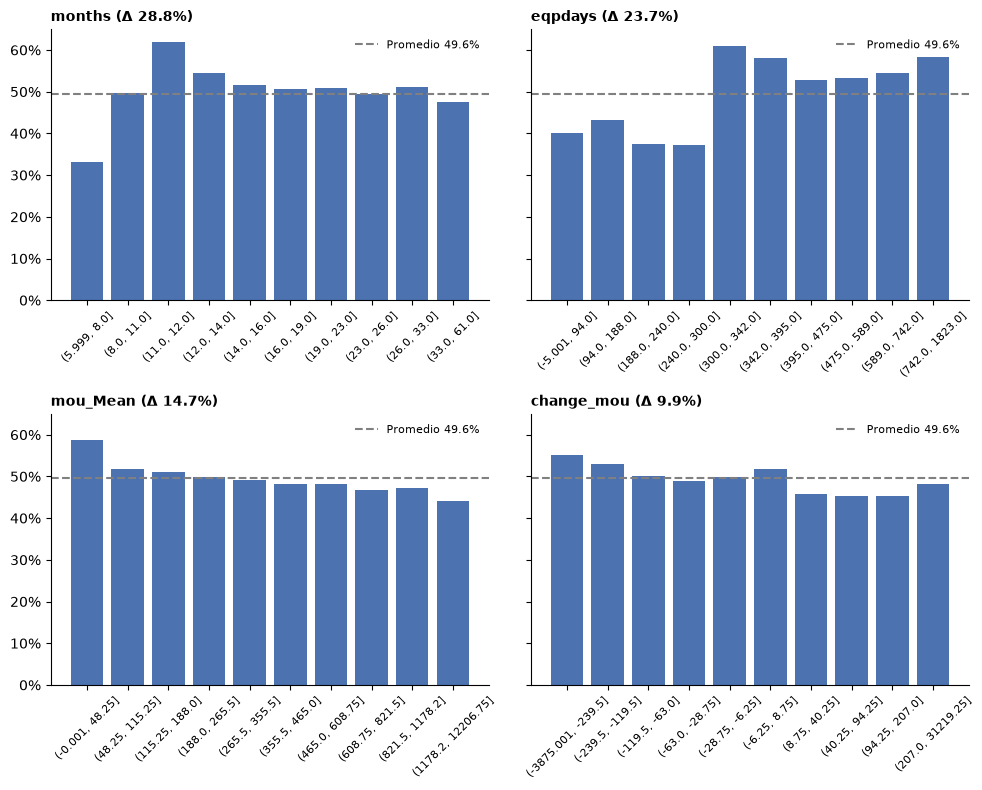

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(10,8), sharey=True)

for col, ax in zip(["months","eqpdays","mou_Mean","change_mou"], axes.flatten()):
    tabla_decil = tasa_por_decil(df, col, dropna=True)
    graficar_tasa(
        tabla=tabla_decil,
        titulo=f"{col} (Δ {dif_tasas[col]:.1%})",
        promedio=promedio_global,
        ax=ax
    )

plt.tight_layout()
plt.show()


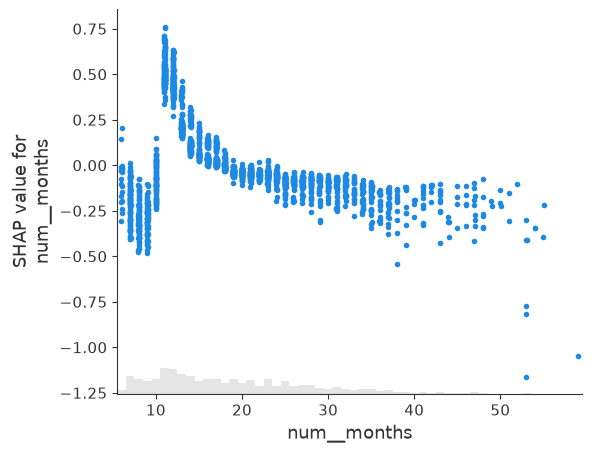

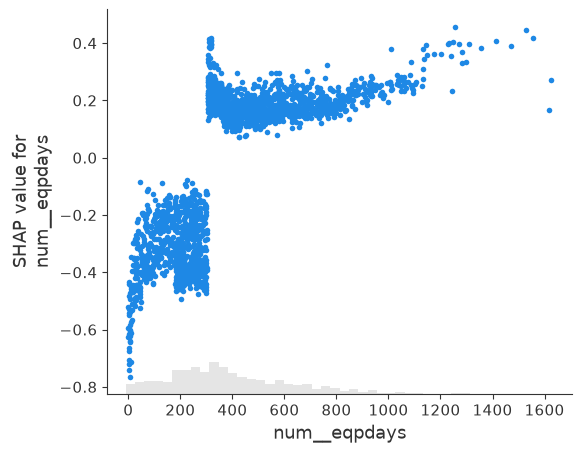

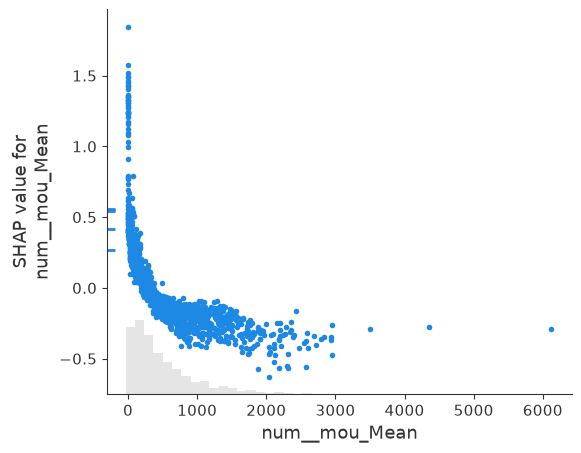

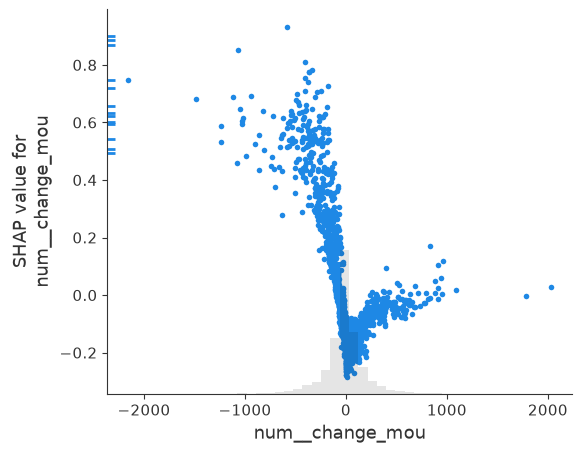

In [21]:
for var in ["num__months","num__eqpdays","num__mou_Mean","num__change_mou"]:
    shap.plots.scatter(valores[:, var])     # forma de una variable

Cuando se usó Regresión Logística, la variable `months` obtuvo un coeficiente negativo de -0.19, diciendo que conforme pasaban los meses menor era el riesgo de churn, pero esto no era cierto para todos los meses según el patrón que vi en el EDA. En el EDA, vi que había un pico de riesgo en el mes 11 y luego de ahí ya empezaba a bajar poco a poco. Ahora, usando LightGBM y analizando con SHAP, se puede ver que el modelo logró captar este pico teniendo un SHAP negativo entre 6 y 9 meses (menor riesgo), saltó a +0.5 en los meses 11 y 12 (mayor riesgo), y luego baja poco a poco.

Los umbrales que encontró el modelo coinciden con los del EDA, se puede ver fácilmente en la comparación de las gráficas de tasa por decil y las gráficas de SHAP por variable, se siguen los mismos patrones de subidas y bajadas en los diferentes deciles.


En la gráfica de change_mou se puede ver que los clientes con SHAP más alto son los que tienen un decremento en el uso mensual respecto a los tres meses anteriores a la observación. Siendo más alto el SHAP conforme más baja el uso de minutos.

In [22]:
probabilidades = pipeline_lgbm.predict_proba(X_muestra)[:, 1]

indice_mayor_riesgo = probabilidades.argmax()
prob_max = probabilidades[indice_mayor_riesgo]

mediana_prob = np.median(probabilidades)
indice_medio_riesgo = np.abs(probabilidades - mediana_prob).argmin()
prob_med = probabilidades[indice_medio_riesgo]

indice_menor_riesgo = probabilidades.argmin()
prob_min = probabilidades[indice_menor_riesgo]


Cliente en la posición [1109] | Probabilidad de churn: 90.6%


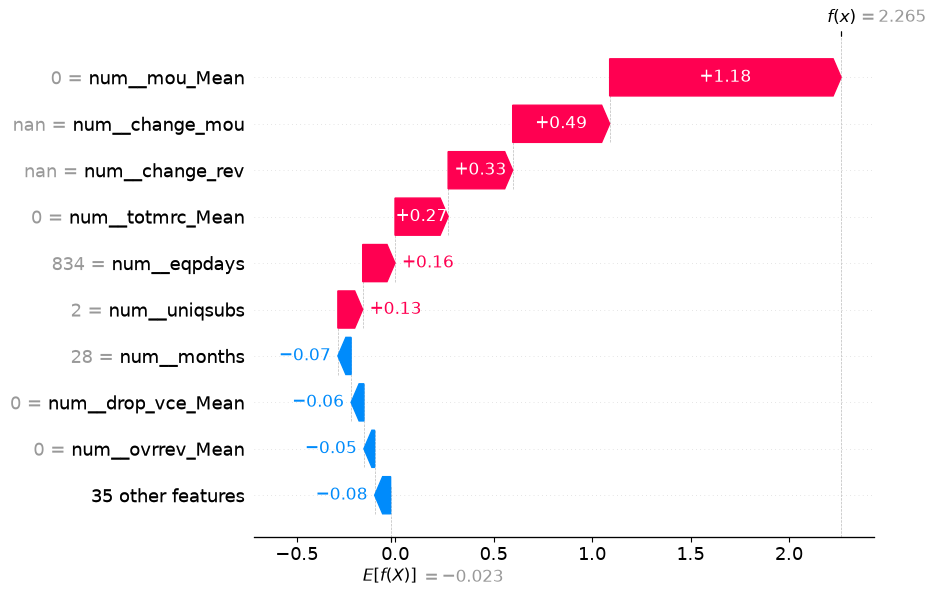

In [23]:
print(f"Cliente en la posición [{indice_mayor_riesgo}] | Probabilidad de churn: {prob_max:.1%}")
shap.plots.waterfall(valores[indice_mayor_riesgo])              # local: un cliente

Este cliente tiene 90.6% de riesgo principalmente por el nulo uso mensual de minutos que ha tenido a pesar de llevar ya más de dos meses con el servicio. Por otro lado, su equipo ya tiene una antiguedad de más de dos años, lo que aumenta el riesgo de cancelación.

Yo no le vería sentido gastar presupuesto de retención en él, se le castiga mucho por el nulo uso de minutos que ha tenido en los 4 meses previos a su observación, pero es importante ver que el cliente ya lleva más de dos años con su servicio. Una opción podría ser proponerle algún plan de renovación de equipo, pero viendo el poco uso que le da a su dispositivo actual, dudo mucho que quiera cambiar de equipo. Se ve que es un perfil de cliente de poco uso de su equipo y que por lo tanto el riesgo de que se cambie, desde ese punto de vista, es bajo, añadiéndole que ya lleva más de dos años con el servicio.

Es importante llevar los datos a la realidad y no simplemente contactar a los "clientes de mayor riesgo" ya que, llevado el modelo a la realidad se le puede dar una interpretación diferente y se puede tomar una decisión combinada entre lo que dice el modelo y el conocimiento sobre el negocio y los clientes. Un cliente que ya lleva muchos años con el servicio, tiene poco uso de minutos y su equipo es viejo, parece ser un cliente que da un muy poco uso a su celular lo cual puede indicar que será muy dificil convenserlo de cambiar de dispositivo porque además eso no asegura que vaya a consumir más minutos.

Otra forma de verlo es que se trate de un abandono silencioso, probablemente el cliente ya dejó de usar la línea y solo falta la cancelación formal, por lo que gastar presupuesto en él es desperdiciarlo, aunque el modelo acierte, ya que este cliente tiene riesgo altísimo y recuperabilidad casi nula.

Cliente en la posición [290] | Probabilidad de fuga: 51.0%


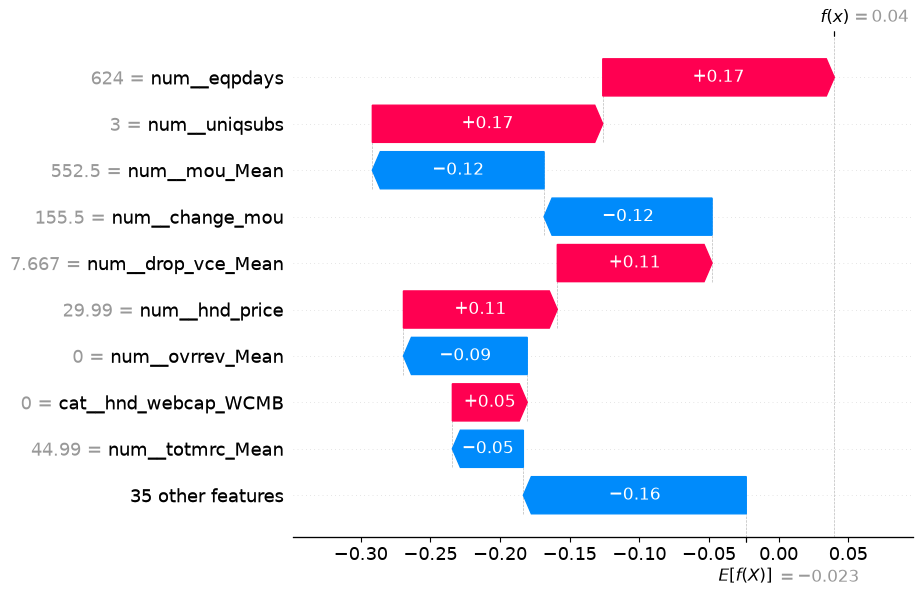

In [24]:
print(f"Cliente en la posición [{indice_medio_riesgo}] | Probabilidad de fuga: {prob_med:.1%}")
shap.plots.waterfall(valores[indice_medio_riesgo])

Este cliente tiene 51% de riesgo porque tiene muchos factores que indican que se podría ir pero otros que indican que se podría quedar. Por un lado, la antiguedad de su equipo es de ya casi tres años siendo este el factor de mayor riesgo. Por otro lado, El número de uso mensual de minutos y el aumento de este respecto a los últimos 3 meses, es lo que reduce su riesgo.

Cliente en la posición [1364] | Probabilidad de fuga: 11.5%


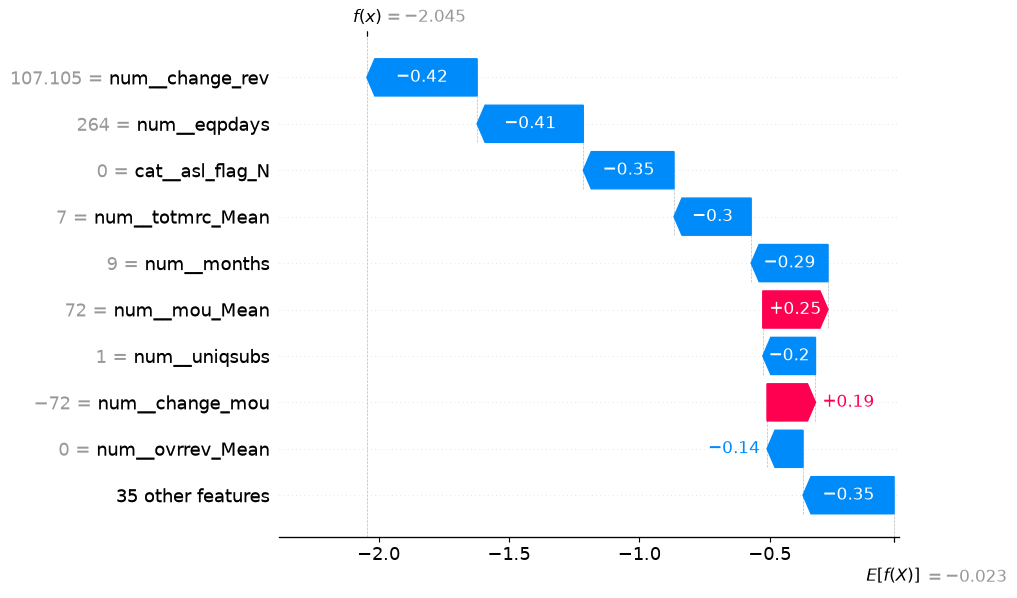

In [25]:
print(f"Cliente en la posición [{indice_menor_riesgo}] | Probabilidad de fuga: {prob_min:.1%}")
shap.plots.waterfall(valores[indice_menor_riesgo])

Este cliente tiene tan solo el 11% de riesgo porque tiene una combinación positiva de factores. Principalmente, ha tenido un aumento en su uso de mensual de minutos, su dispositivo es relativamente nuevo con menos de un año de antigüedad y no tiene límite de gasto de cuenta.

In [26]:
segmentos = pd.DataFrame({
    "score": pipeline_lgbm.predict_proba(X_test)[:, 1],
    "churn": y_test,
    "rev_Mean": X_test["rev_Mean"],
}, index=X_test.index)

In [27]:
umbral_riesgo = segmentos["score"].quantile(0.80)       # el 20% de mayor riesgo
mediana_valor = segmentos["rev_Mean"].median()

segmentos["riesgo"] = np.where(segmentos["score"] >= umbral_riesgo, "Alto", "Bajo")
segmentos["valor"] = np.where(segmentos["rev_Mean"] > mediana_valor, "Alto", "Bajo")

Con este código, los clientes con rev_Mean vacío pasan a valor 'Bajo' lo considero correcto ya que ese vacío puede significar un cero que el mismo modelo le da peso para mayor riesgo.

In [28]:
segmentos["ingreso_perdido"] = segmentos["rev_Mean"] * segmentos["churn"] # 0 si no se fue

In [29]:
matriz = segmentos.groupby(["riesgo", "valor"]).agg(
    n_clientes=("churn", "size"),
    tasa_churn=("churn", "mean"),
    ingreso_en_juego=("ingreso_perdido", "sum"),
)
matriz["ingreso_por_cliente"] = matriz["ingreso_en_juego"] / matriz["n_clientes"]

In [30]:
matriz

n_clientes  tasa_churn  ingreso_en_juego  ingreso_por_cliente
riesgo valor                                                               
Alto   Alto         1947    0.702106     118422.887500            60.823260
       Bajo         2053    0.737944      45169.932500            22.001915
Bajo   Alto         8020    0.435037     295409.095833            36.834052
       Bajo         7980    0.443734     111385.374167            13.958067

Mirando la segunda y la tercera fila: un cliente de riesgo bajo y valor alto tiene más ingreso en juego ($36.8) que uno de riesgo alto y valor bajo ($22.0). Es decir, el valor del cliente pesa tanto como su riesgo. Ordenar solo por riesgo mandaría el presupuesto al cuadrante de $22 antes que al de $37.

Además, el cuadrante de riesgo alto y valor bajo tiene la tasa de churn más alta de todas (74%): ahí es donde caen los clientes de abandono silencioso, como el de cero minutos que se vió arriba.

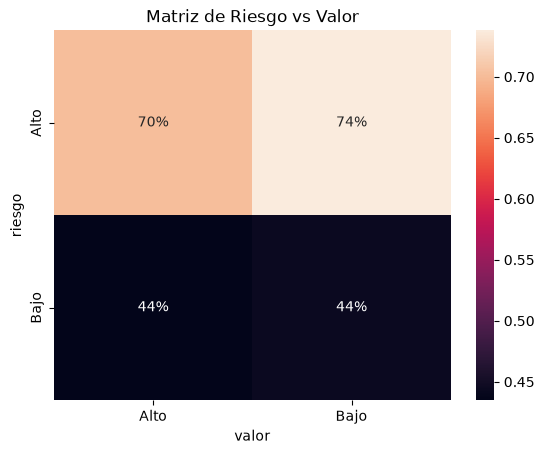

In [31]:
import seaborn as sns

sns.heatmap(
    matriz["tasa_churn"].unstack(),
    annot=True, 
    fmt=".0%"
)
plt.title("Matriz de Riesgo vs Valor")

plt.show()

Como ya se vió, irse simplemente por los clientes de mayor riesgo no es tan buena opción.Viendo este mapa de calor, definitivamente considero que es mucho mejor aplicar la campaña de retención a los clientes de mayor riesgo de churn y, de esos, a los de mayor valor. Para este modelo, dado su conjunto de entrenamiento, sería tomar primero al 20% de los clientes con mayor riesgo y, de estos, a aquellos que tengan un rev_Mean mayor a la media.